In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel('Vehicle_Data.xlsx')

df.columns = df.columns.str.strip()

df = df.drop_duplicates().copy()

df['Price'] = (
    df['Price'].astype(str)
    .str.replace('KSh', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df['Mileage'] = (
    df['Mileage'].astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
    .replace('Unavailable', np.nan)
)
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce')

df['YOM'] = pd.to_numeric(df['YOM'], errors='coerce')

df = df.dropna(subset=['Model', 'Make', 'YOM', 'Price', 'Mileage']).copy()
df = df[(df['YOM'] >= 1960) & (df['YOM'] <= 2026)]
df = df[(df['Price'] > 0) & (df['Mileage'] >= 0)]

df['Make'] = df['Make'].str.strip()
df['Model'] = df['Model'].str.strip()
df['Location'] = df['Location'].str.split(',').str[0].str.strip()


print(df.head())

     Model    Make     YOM   Color          Used Transmission   Mileage  \
0  X-Trail  Nissan  2014.0   Black  Foreign Used    Automatic  136000.0   
1    Teana  Nissan  2014.0  Silver  Foreign Used    Automatic   85000.0   
2    Teana  Nissan  2013.0    Gray  Foreign Used    Automatic   90231.0   
3  X-Trail  Nissan  2014.0   White  Foreign Used    Automatic   52000.0   
6  Qashqai  Nissan  2014.0   Black  Foreign Used       Manual  115000.0   

  Location      Price  
0  Nairobi  2050000.0  
1  Nairobi  1380000.0  
2  Nairobi   995000.0  
3  Nairobi  2500000.0  
6  Nairobi  1950000.0  


Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor



# Load dataset
df = pd.read_excel('Vehicle_Data.xlsx')

print(df.head())
print(df.shape)
import seaborn as sns

# Load dataset
df = pd.read_excel('Vehicle_Data.xlsx')

# Preview
print(df.head())
print(df.shape)

     Model    Make   YOM   Color          Used Transmission      Mileage  \
0  X-Trail  Nissan  2014   Black  Foreign Used    Automatic       136000   
1    Teana  Nissan  2014  Silver  Foreign Used    Automatic        85000   
2    Teana  Nissan  2013    Gray  Foreign Used    Automatic        90231   
3  X-Trail  Nissan  2014   White  Foreign Used    Automatic        52000   
4     Note  Nissan  2014   White  Foreign Used    Automatic  Unavailable   

               Location          Price  
0        Nairobi, Karen  KSh 2,050,000  
1     Nairobi, Kilimani  KSh 1,380,000  
2    Nairobi, Ridgeways    KSh 995,000  
3      Nairobi, Jamhuri  KSh 2,500,000  
4  Mombasa, Mombasa CBD  KSh 1,100,000  
(46685, 9)
     Model    Make   YOM   Color          Used Transmission      Mileage  \
0  X-Trail  Nissan  2014   Black  Foreign Used    Automatic       136000   
1    Teana  Nissan  2014  Silver  Foreign Used    Automatic        85000   
2    Teana  Nissan  2013    Gray  Foreign Used    Automati


 Data Cleaning and Preprocessing

In [3]:
df.columns = df.columns.str.strip()

# Remove duplicates
df = df.drop_duplicates().copy()

# Clean Price
df['Price'] = (
    df['Price'].astype(str)
    .str.replace('KSh', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

# Clean Mileage
df['Mileage'] = (
    df['Mileage'].astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
    .replace(['Unavailable', 'N/A', 'None', ''], np.nan)
)
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce')

# Convert YOM
df['YOM'] = pd.to_numeric(df['YOM'], errors='coerce')

# Keep county only
df['Location'] = (
    df['Location'].astype(str)
    .str.split(',')
    .str[0]
    .str.strip()
    .str.title()
)

# Standardize text columns
for col in ['Make', 'Model', 'Transmission', 'Fuel Type']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# Remove rows with missing critical values
df = df.dropna(subset=['Make', 'Model', 'YOM', 'Price', 'Mileage'])
# Convert empty strings and 'nan' strings back to missing values
for col in ['Model', 'Make', 'Color', 'Used', 'Transmission', 'Location']:
    df[col] = (
        df[col]
        .replace('nan', np.nan)
        .replace('', np.nan)
    )

# Fill categorical missing values
for col in ['Color', 'Used', 'Transmission', 'Location']:
    df[col] = df[col].fillna('Unknown')

# Final check
print(df.isna().sum()[df.isna().sum() > 0])
# Keep valid values
df = df[
    (df['YOM'].between(1960, 2026)) &
    (df['Price'] > 0) &
    (df['Mileage'] >= 0)
].copy()

# Create engineered features
current_year = 2026
df['Age'] = current_year - df['YOM']
df['Mileage_per_Year'] = df['Mileage'] / (df['Age'] + 1)

# Log transform
df['LogPrice'] = np.log1p(df['Price'])
df['LogMileage'] = np.log1p(df['Mileage'])

df.reset_index(drop=True, inplace=True)

print(df.shape)
print(df[['Price', 'LogPrice']].head())

Series([], dtype: int64)
(32222, 13)
       Price   LogPrice
0  2050000.0  14.533351
1  1380000.0  14.137595
2   995000.0  13.810499
3  2500000.0  14.731802
4  1950000.0  14.483340


EDA

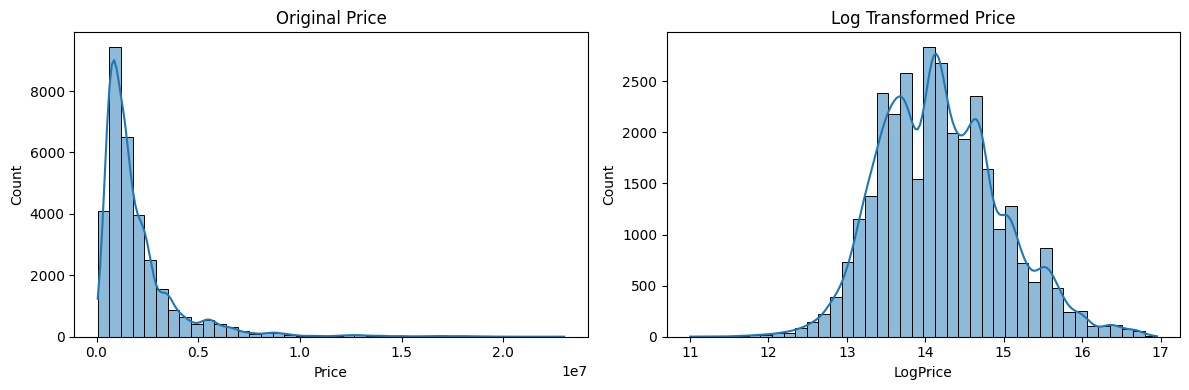

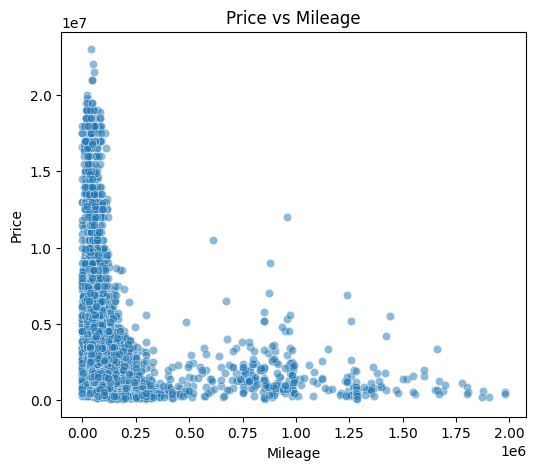

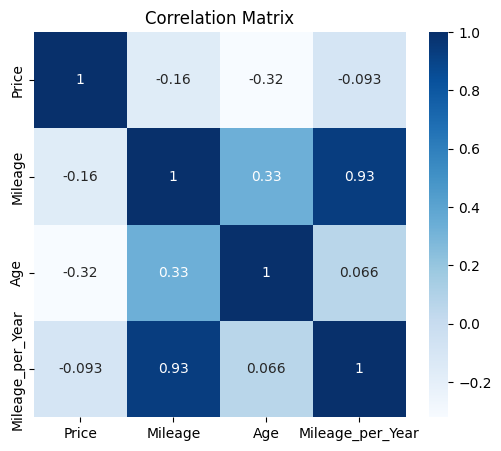

Make
Toyota           14070
Nissan            4007
Subaru            2160
Mazda             2014
Honda             1496
Volkswagen        1255
Mitsubishi        1226
Mercedes-Benz     1165
Suzuki            1104
Bmw               1047
Name: count, dtype: int64


In [4]:
# Compare original and log-transformed price
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.histplot(df['Price'], bins=40, kde=True)
plt.title('Original Price')

plt.subplot(1,2,2)
sns.histplot(df['LogPrice'], bins=40, kde=True)
plt.title('Log Transformed Price')

plt.tight_layout()
plt.show()

# Price vs Mileage
plt.figure(figsize=(6,5))
sns.scatterplot(x='Mileage', y='Price', data=df, alpha=0.5)
plt.title('Price vs Mileage')
plt.show()

# Correlation matrix
corr = df[['Price', 'Mileage', 'Age', 'Mileage_per_Year']].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='Blues')
plt.title('Correlation Matrix')
plt.show()

# Top makes
print(df['Make'].value_counts().head(10))

Features and Target

In [5]:
X = df[['Make', 'Model', 'Transmission', 'Used',
        'Location', 'LogMileage', 'Age', 'Mileage_per_Year']]

y = df['LogPrice']

numeric_features = ['LogMileage', 'Age', 'Mileage_per_Year']
categorical_features = ['Make', 'Model', 'Transmission', 'Used', 'Location']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Train the Models

In [6]:
# Multiple Linear Regression
mlr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Random Forest
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective='reg:squarederror'
    ))
])

# Train models
mlr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print('Models trained successfully.')

Models trained successfully.


Five-Fold Cross-Validation

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in [('MLR', mlr_model),
                    ('Random Forest', rf_model),
                    ('XGBoost', xgb_model)]:

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )

    print(f'{name} CV RMSE: {-scores.mean():.4f} ± {scores.std():.4f}')

MLR CV RMSE: 0.2154 ± 0.0059
Random Forest CV RMSE: 0.2725 ± 0.0051
XGBoost CV RMSE: 0.2339 ± 0.0059


Evaluation on Test Set

In [8]:
def evaluate_model(name, model, X_test, y_test):
    y_pred_log = model.predict(X_test)

    # Convert back to original price scale
    y_pred = np.expm1(y_pred_log)
    y_true = np.expm1(y_test)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)

    print(f'\n{name}')
    print(f'RMSE: KES {rmse:,.0f}')
    print(f'MAPE: {mape:.2f}%')
    print(f'R²: {r2:.4f}')

    return y_true, y_pred

y_true, mlr_pred = evaluate_model('Multiple Linear Regression', mlr_model, X_test, y_test)
_, rf_pred = evaluate_model('Random Forest', rf_model, X_test, y_test)
_, xgb_pred = evaluate_model('XGBoost', xgb_model, X_test, y_test)


Multiple Linear Regression
RMSE: KES 775,967
MAPE: 14.74%
R²: 0.8579

Random Forest
RMSE: KES 809,880
MAPE: 20.03%
R²: 0.8452

XGBoost
RMSE: KES 817,095
MAPE: 17.26%
R²: 0.8424


Rare-Segment Evaluation

In [9]:
# Define rare brands (<2% of dataset)
brand_freq = df['Make'].value_counts(normalize=True)

rare_brands = brand_freq[brand_freq < 0.02].index.tolist()

test_df = X_test.copy()
test_df['Actual'] = np.expm1(y_test)
test_df['Predicted'] = xgb_pred
test_df['Make'] = X_test['Make']

test_df['Segment'] = np.where(
    test_df['Make'].isin(rare_brands),
    'Rare',
    'Common'
)

# Compute MAPE by segment
segment_results = test_df.groupby('Segment').apply(
    lambda g: np.mean(np.abs((g['Actual'] - g['Predicted']) / g['Actual'])) * 100
)

print('\nMAPE by Segment')
print(segment_results)


MAPE by Segment
Segment
Common    16.957828
Rare      21.825278
dtype: float64


/tmp/ipykernel_15051/765250752.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  segment_results = test_df.groupby('Segment').apply(


Feature Importance (Random Forest)

                     Feature  Importance
1                   num__Age    0.264156
311          cat__Model_Land    0.193708
15      cat__Make_Land Rover    0.074768
16           cat__Make_Lexus    0.043870
25          cat__Make_Suzuki    0.032366
21          cat__Make_Nissan    0.031693
18   cat__Make_Mercedes-Benz    0.028144
284         cat__Model_Hilux    0.026997
278       cat__Model_Harrier    0.023438
212         cat__Model_Demio    0.018579
26          cat__Make_Toyota    0.017198
250           cat__Model_Fit    0.016406
7         cat__Make_Daihatsu    0.016001
0            num__LogMileage    0.015240
497       cat__Model_X-Trail    0.013308


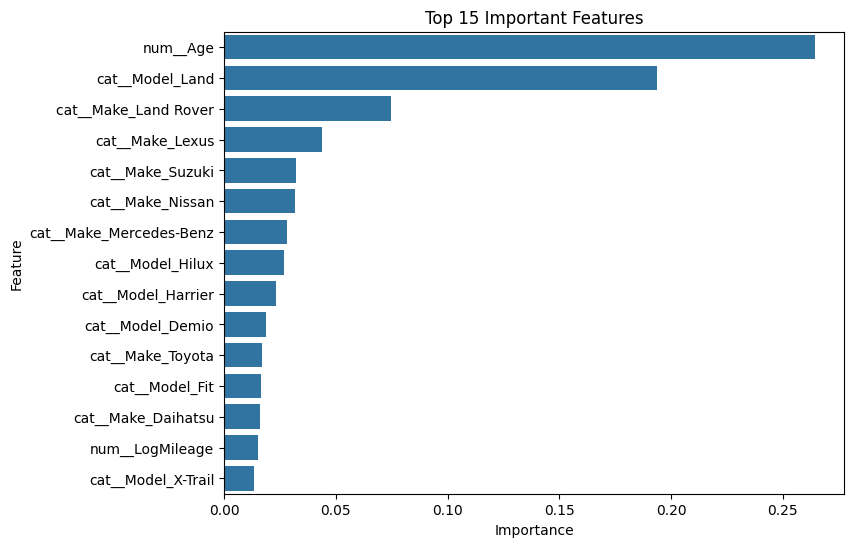

In [10]:
# Get trained Random Forest
rf_estimator = rf_model.named_steps['model']

# Get feature names after preprocessing
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_estimator.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df.head(15))

# Plot top 15 features
plt.figure(figsize=(8,6))
sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)
plt.title('Top 15 Important Features')
plt.show()

SHAP Explainability

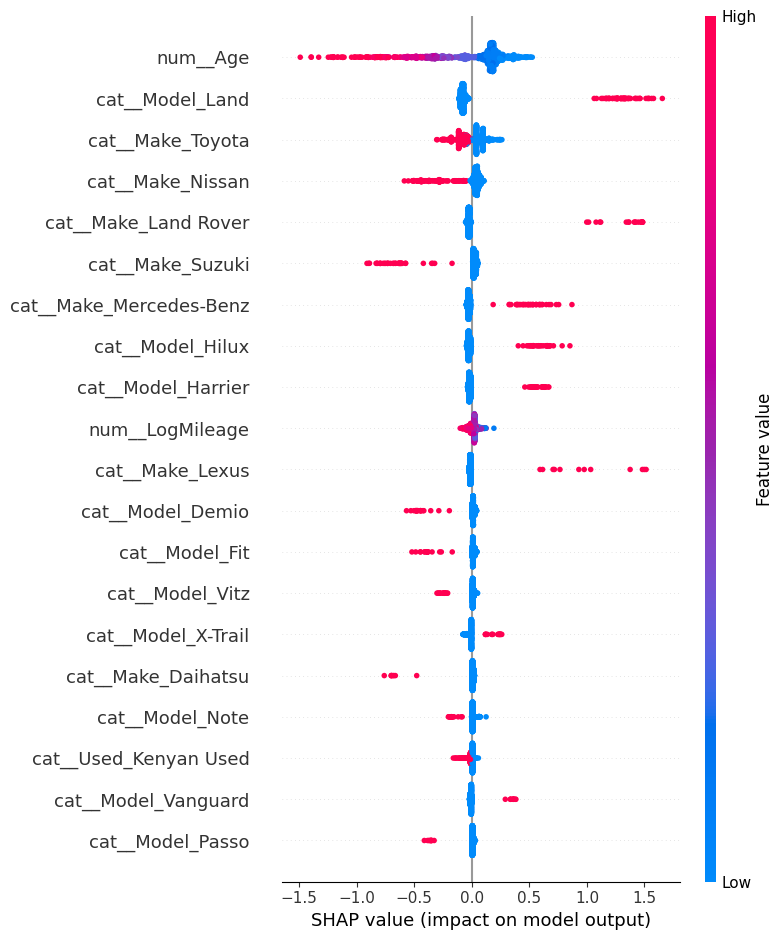

In [11]:
# Install SHAP if needed
!pip install shap

import shap

# Transform training data
X_train_transformed = rf_model.named_steps['preprocessor'].transform(X_train)

# Convert to dense array
X_train_transformed_dense = X_train_transformed.toarray()

# Use a sample for speed
sample_size = min(1000, X_train_transformed_dense.shape[0])
X_sample = X_train_transformed_dense[:sample_size]

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_estimator)
shap_values = explainer.shap_values(X_sample)

# Summary plot
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names
)

Actual vs Predicted Plot

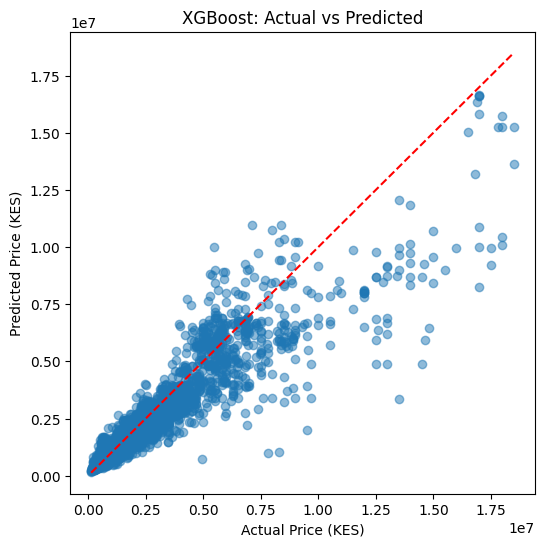

In [12]:
plt.figure(figsize=(6,6))
plt.scatter(y_true, xgb_pred, alpha=0.5)

plt.plot(
    [y_true.min(), y_true.max()],
    [y_true.min(), y_true.max()],
    'r--'
)

plt.xlabel('Actual Price (KES)')
plt.ylabel('Predicted Price (KES)')
plt.title('XGBoost: Actual vs Predicted')
plt.show()